In [7]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [8]:
# Load the dataset
iris = load_iris(as_frame=True)

# Store measurements and species
X = iris.data
y = iris.target

# Display the first five rows
print(X.head())

# Display the flower species
print(iris.target_names)

# Check dataset size
print("Dataset shape:", X.shape)

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
['setosa' 'versicolor' 'virginica']
Dataset shape: (150, 4)


In [9]:
# Display column names and data types
print(X.info())

# Check for missing values
print(X.isnull().sum())

# Show basic statistics
print(X.describe())

# Count flowers in each species
print(pd.Series(
    iris.target_names[y],
    name="Species"
).value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB
None
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%

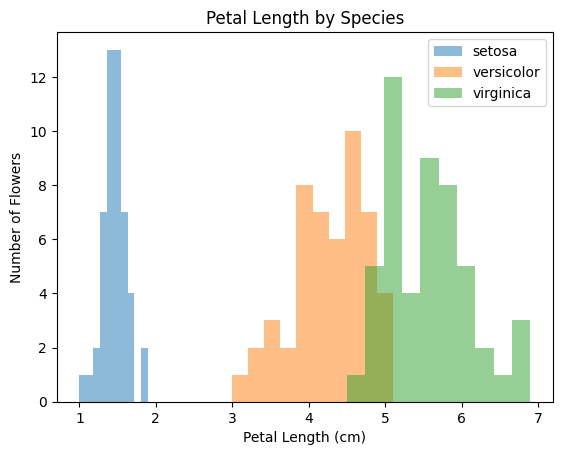

In [11]:
import matplotlib.pyplot as plt

for i, species in enumerate(iris.target_names):
    plt.hist(
        X["petal length (cm)"].to_numpy()[y.to_numpy() == i]
        if hasattr(y, "to_numpy")
        else X["petal length (cm)"].to_numpy()[y == i],
        alpha=0.5,
        label=species
    )

plt.xlabel("Petal Length (cm)")
plt.ylabel("Number of Flowers")
plt.title("Petal Length by Species")
plt.legend()
plt.show()

In [12]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the sizes
print("Training data:", len(X_train))
print("Testing data:", len(X_test))

Training data: 120
Testing data: 30


In [13]:
from sklearn.tree import DecisionTreeClassifier

# Create the model
model = DecisionTreeClassifier(random_state=42)

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [14]:
from sklearn.metrics import accuracy_score

# Predict flower species using test data
y_pred = model.predict(X_test)

# Calculate model accuracy
accuracy = accuracy_score(y_test, y_pred)

# Display accuracy
print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 93.33 %


In [15]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



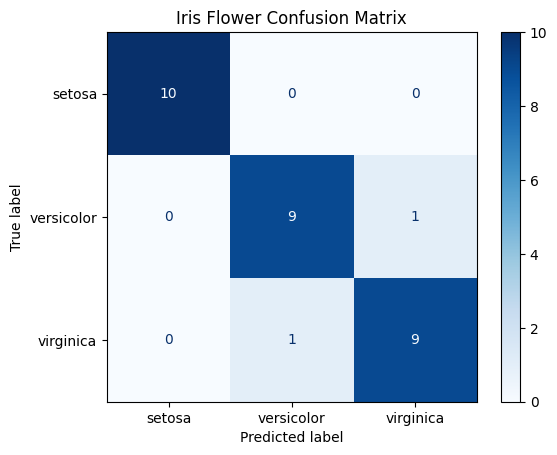

In [16]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

disp.plot(cmap="Blues")
plt.title("Iris Flower Confusion Matrix")
plt.show()

In [17]:
# Measurements of a new flower
new_flower = [[5.1, 3.5, 1.4, 0.2]]

# Predict the flower species
prediction = model.predict(new_flower)

# Display the result
print("Predicted flower species:",
      iris.target_names[prediction[0]])

Predicted flower species: setosa


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


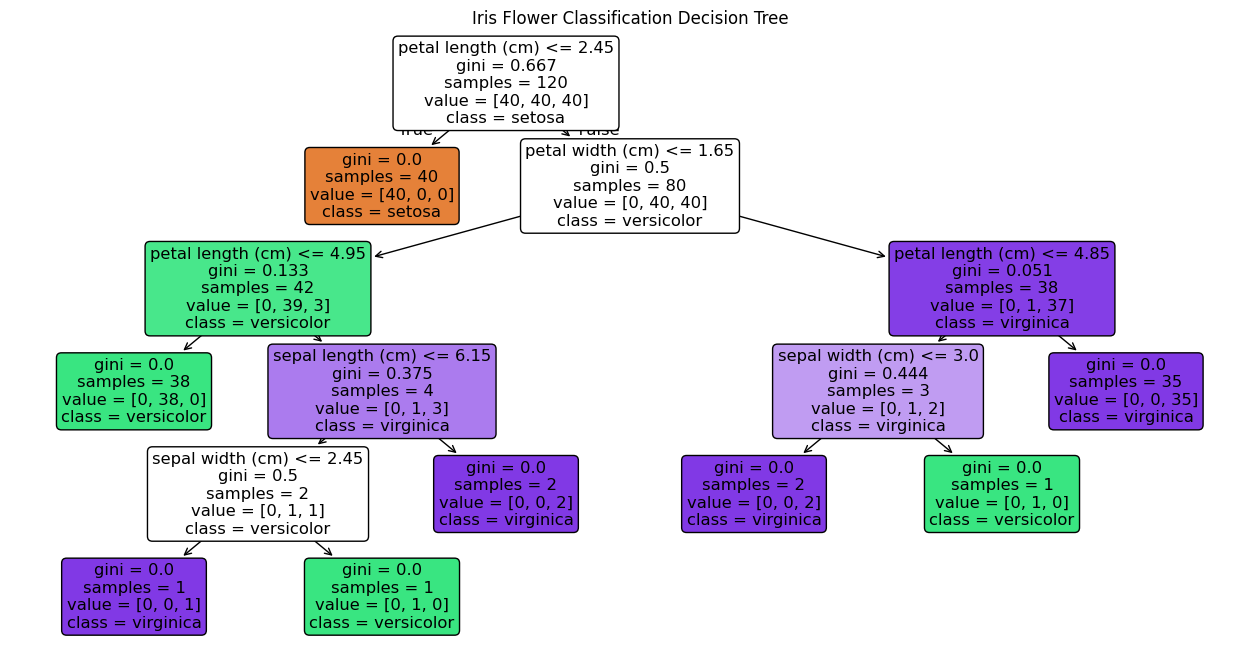

In [18]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 8))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=iris.target_names,
    filled=True,
    rounded=True
)

plt.title("Iris Flower Classification Decision Tree")
plt.show()